# Heart-Disease Risk Screening Using Machine Learning (CDC BRFSS)

Author: Ashis Das, and Hanmant Mhalappa Kattimani, Ram Prasanth G

Course: AAI-540 Machine Learning Operations

University: University of San Diego

Instructor: Dr. Raj Garg

---

This project builds a supervised **binary classification** system that estimates
whether an adult is likely to report **coronary heart disease or myocardial
infarction (CHD/MI)** using non-invasive demographic, behavioural and
general-health information from the CDC **Behavioral Risk Factor Surveillance
System (BRFSS)**.

The intended application is **preliminary population-level risk screening and
prioritisation** for further medical evaluation. The model does **not** provide a
medical diagnosis.

The end-to-end MLOps pipeline is:

**Raw BRFSS XPT (2021, 2022, 2023) → Ingestion & Harmonisation → EDA →
Feature Engineering (leakage-controlled) → Model Training & Comparison →
Temporal Test Evaluation (2023) → Fairness / Subgroup Analysis →
Model Selection → Monitoring & CI/CD design**


## 1. Introduction

Cardiovascular disease is a leading cause of death worldwide, yet many adults
remain unaware of their elevated risk until they experience a serious event.
Routinely collected lifestyle, demographic and general-health information can
provide useful signals for identifying individuals who are more likely to have
a history of coronary heart disease or myocardial infarction.

This project investigates whether machine-learning models trained on the CDC
BRFSS survey can flag adults at higher risk of reported heart disease, so that
scarce clinical screening capacity can be prioritised. Because the positive
class is relatively rare (~8-9% of respondents), the work emphasises
**minority-class detection** (recall / sensitivity and precision-recall AUC)
rather than raw accuracy.


## 2. Project Objective

The objective is to develop and evaluate a binary classifier that predicts the
CDC-calculated heart-disease indicator **`_MICHD`** from non-invasive features.

Specifically, the project aims to:

- Ingest and harmonise three annual BRFSS survey files (2021, 2022, 2023).
- Derive a clean binary target and remove any target-leaking variables.
- Explore prevalence, class balance, missingness and risk-factor associations.
- Build a leakage-controlled preprocessing and feature pipeline.
- Train a logistic-regression baseline and four tree-based challengers with
  class weighting.
- Evaluate models on a **temporal** 2023 test set to measure generalisation to
  a later year.
- Assess **fairness** across sex and age subgroups.
- Select a final model on predictive performance, calibration, stability and
  subgroup behaviour — not accuracy alone.


## 3. Project Methodology

The project follows a structured MLOps workflow.

### Stage 1 — Data Collection
Three annual BRFSS SAS-XPT files (2021, 2022, 2023) are downloaded from the CDC.

### Stage 2 — Data Preprocessing & Harmonisation
Only variables consistently available across **all three** years are retained.
"Don't know / refused" survey codes are converted to missing values, and the
binary target is derived from `_MICHD`.

### Stage 3 — Exploratory Data Analysis
Prevalence by year, class balance, missing-data patterns, feature distributions
and risk-factor associations are examined.

### Stage 4 — Feature Engineering
A scikit-learn `ColumnTransformer` imputes and scales continuous features and
imputes and one-hot-encodes categorical survey codes. All statistics are learned
on the training data only to avoid leakage.

### Stage 5 — Model Training
A logistic-regression baseline is compared with Decision Tree, Random Forest,
Gradient Boosting and XGBoost, all made imbalance-aware via class weighting.

### Stage 6 — Temporal Evaluation & Fairness
Models are trained on 2021+2022 and tested on the held-out 2023 data. Subgroup
performance is analysed by sex and age.


## 4. Dataset

The project uses the CDC **Behavioral Risk Factor Surveillance System (BRFSS)**,
a large annual telephone health survey of non-institutionalised US adults.

| Dataset | Raw records |
|---|---|
| BRFSS 2021 | 438,693 |
| BRFSS 2022 | 445,132 |
| BRFSS 2023 | 433,323 |
| **Total** | **1,317,148** |

The prediction target is the CDC-calculated variable **`_MICHD`**:

| Class | Meaning |
|---|---|
| 0 | No reported coronary heart disease or myocardial infarction |
| 1 | Reported coronary heart disease or myocardial infarction |

**Temporal split.** 2021 and 2022 are used for model development; **2023 is held
out as a temporal test set** to provide a realistic estimate of how the model
generalises to data collected in a later year.

**Harmonisation note.** BRFSS collects blood-pressure and cholesterol questions
only in odd years, so they are **absent from the 2022 core file**. To maintain a
single feature schema valid for all three years, hypertension and high
cholesterol are intentionally excluded from the common feature set. This
trade-off is documented as a project limitation.


## 5. Import Required Libraries

In [1]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Make the project `src` package importable when running from notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))

from src import config as C
from src import data_ingestion, features as F, train as T, eda, fairness

print("Project root:", PROJECT_ROOT)
print("Train years:", C.TRAIN_YEARS, "| Test year:", C.TEST_YEARS)

Project root: /home/ekattim/.kiro/USD_Project/heart_disease_mlops
Train years: [2021, 2022] | Test year: [2023]


### Interpretation

All analysis and modelling utilities live in the reusable `src/` package so
that the notebook, the command line and a future CI/CD pipeline all execute the
**same** code paths. This is a core MLOps principle: the notebook is a thin
orchestration layer over version-controlled, testable modules.

## 6. Reproducibility

In [2]:
RANDOM_STATE = C.RANDOM_STATE
np.random.seed(RANDOM_STATE)
print("Global random seed:", RANDOM_STATE)

Global random seed: 42


### Interpretation

A single random seed is defined in `config.py` and reused across every model
and split, so results are reproducible from run to run.

## 7. Data Ingestion & Harmonisation

In [3]:
# Reads the three XPT files, harmonises variables, derives the target and
# writes tidy parquet files. If the processed parquet already exists it is
# reused; set FORCE_REINGEST = True to rebuild from the raw XPT files.
FORCE_REINGEST = False
_combined_path = C.PROCESSED_DIR / "brfss_combined.parquet"
if _combined_path.exists() and not FORCE_REINGEST:
    combined = pd.read_parquet(_combined_path)
    print("Loaded cached processed data:", f"{len(combined):,}", "rows")
else:
    combined = data_ingestion.run(save=True)
combined.head()

Loaded cached processed data: 1,302,907 rows


,bmi,mental_health_days,phys_health_days,age_group,sex,gen_health,smoked_100,smoker_status,diabetes,diff_walk,phys_activity,kidney_disease,income_group,education_group,has_personal_doctor,heart_disease,survey_year
0,14.54,10.0,20.0,11.0,2.0,5.0,1.0,3.0,3.0,2.0,2.0,2.0,3.0,2.0,1.0,0,2021
1,NaN,0.0,0.0,10.0,2.0,3.0,2.0,4.0,1.0,1.0,1.0,1.0,NaN,4.0,2.0,1,2021
2,28.29,0.0,0.0,11.0,2.0,2.0,2.0,4.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,1,2021
3,33.47,10.0,0.0,9.0,2.0,2.0,2.0,4.0,1.0,2.0,1.0,2.0,5.0,2.0,1.0,0,2021
4,28.73,0.0,30.0,12.0,1.0,5.0,2.0,4.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,1,2021


### Interpretation

The ingestion step converts three raw SAS-XPT files (~1 GB each) into compact,
analysis-ready parquet files. Only the harmonised feature set plus the target
and survey year are kept. `_MICHD` is mapped to a clean 0/1 label and rows with
an unknown label are dropped.

## 8. Dataset Overview

In [4]:
df = F.load_processed()
print("Rows:", f"{len(df):,}", "| Columns:", df.shape[1])
print("\nRows per survey year:")
print(df["survey_year"].value_counts().sort_index())
print("\nFeature dtypes:")
df[C.ALL_FEATURES].dtypes

Rows: 1,302,907 | Columns: 17

Rows per survey year:
survey_year
2021    434058
2022    440111
2023    428738
Name: count, dtype: int64

Feature dtypes:


bmi                    float64
mental_health_days     float64
phys_health_days       float64
age_group              float64
sex                    float64
gen_health             float64
smoked_100             float64
smoker_status          float64
diabetes               float64
diff_walk              float64
phys_activity          float64
kidney_disease         float64
income_group           float64
education_group        float64
has_personal_doctor    float64
dtype: object

### Interpretation

After harmonisation and dropping unlabelled rows the combined dataset contains
about 1.30 million respondents across the three years — far exceeding the
project's minimum volume requirement and providing ample positive cases despite
the class imbalance.

## 9. Target Definition and Leakage Control

In [5]:
print("Target variable:", C.TARGET, "(derived from _MICHD)")
print("Leakage columns excluded from features:", C.LEAKAGE_COLS)
print("\nModelling features (%d):" % len(C.ALL_FEATURES))
for f_ in C.ALL_FEATURES:
    print("  -", f_)

Target variable: heart_disease (derived from _MICHD)
Leakage columns excluded from features: ['_MICHD', 'CVDINFR4', 'CVDCRHD4']

Modelling features (15):
  - bmi
  - mental_health_days
  - phys_health_days
  - age_group
  - sex
  - gen_health
  - smoked_100
  - smoker_status
  - diabetes
  - diff_walk
  - phys_activity
  - kidney_disease
  - income_group
  - education_group
  - has_personal_doctor


### Interpretation

`CVDINFR4`, `CVDCRHD4` and `_MICHD` directly define the target and are therefore
**never** used as inputs. Excluding them prevents target leakage that would
otherwise produce misleadingly perfect scores.

## 10. Heart-Disease Prevalence by Year

,mean,count,prevalence
survey_year,,,
2021,0.081379,434058,8.14
2022,0.090320,440111,9.03
2023,0.084693,428738,8.47


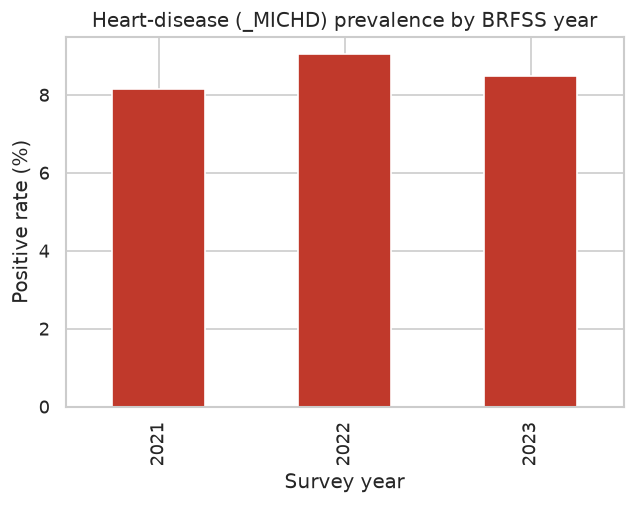

In [6]:
tab = df.groupby("survey_year")[C.TARGET].agg(["mean", "count"])
display(tab.assign(prevalence=lambda d: (d["mean"]*100).round(2)))
from IPython.display import Image
Image(str(C.FIGURES_DIR / "01_prevalence_by_year.png"))

### Interpretation

Prevalence is stable across years — 8.14% (2021), 9.03% (2022) and 8.47%
(2023). The mild year-to-year variation is exactly the kind of shift the
temporal 2023 test set is designed to stress-test.

## 11. Class Balance

heart_disease
0    1191522
1     111385
Name: count, dtype: int64
Positive rate: 8.55%


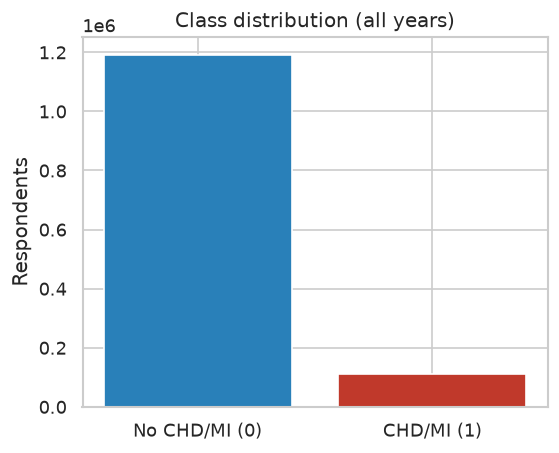

In [7]:
counts = df[C.TARGET].value_counts().sort_index()
print(counts)
print("Positive rate: %.2f%%" % (100*df[C.TARGET].mean()))
Image(str(C.FIGURES_DIR / "02_class_balance.png"))

### Interpretation

Only ~8.5% of respondents are positive. This strong imbalance is why the project
prioritises recall and PR-AUC and applies class weighting; plain accuracy would
be maximised by a useless majority-class predictor.

## 12. Missing-Data Pattern

,missing_%
income_group,20.86
bmi,10.26
smoker_status,6.28
smoked_100,6.17
diff_walk,4.63
phys_health_days,2.29
age_group,1.96
mental_health_days,1.85
has_personal_doctor,0.90
education_group,0.51


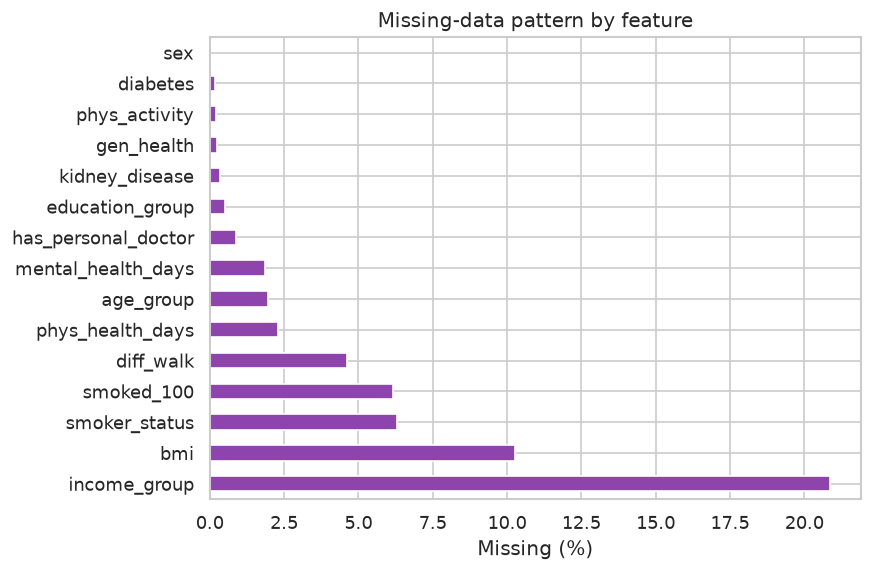

In [8]:
miss = df[C.ALL_FEATURES].isna().mean().sort_values(ascending=False)
display((miss*100).round(2).to_frame("missing_%"))
Image(str(C.FIGURES_DIR / "03_missingness.png"))

### Interpretation

Income (~21%) and BMI (~10%) have the most missingness, reflecting survey
non-response. Missing values are imputed inside the pipeline using
**training-set** statistics only, so no test-set information leaks backward.

## 13. Continuous Feature Distributions by Class

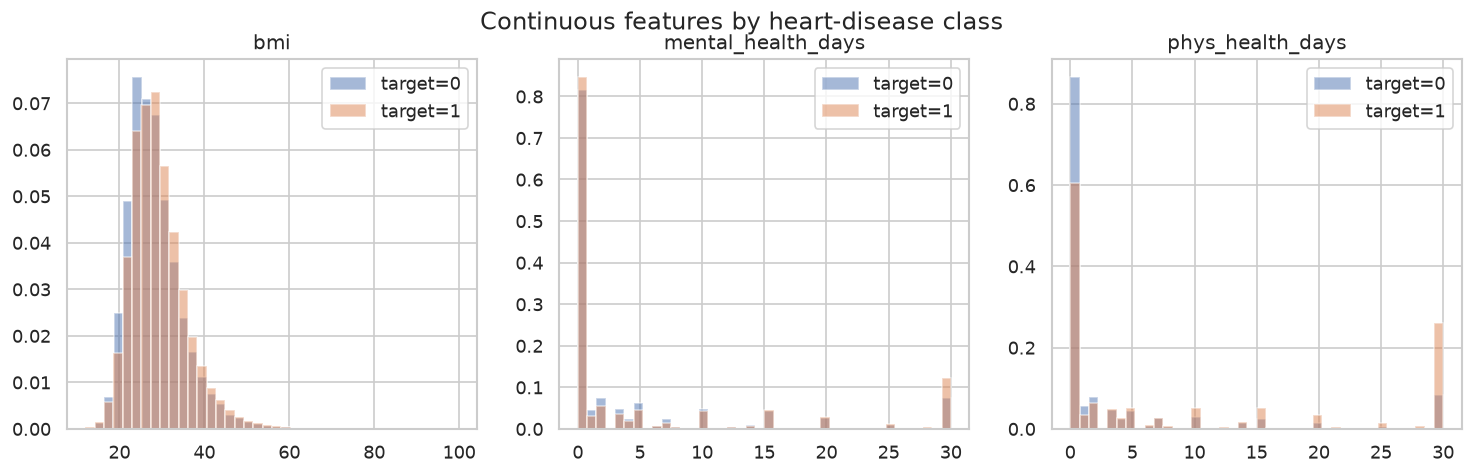

In [9]:
Image(str(C.FIGURES_DIR / "04_continuous_by_class.png"))

### Interpretation

Respondents reporting heart disease tend to have more poor-physical-health days
and slightly higher BMI. The distributions overlap heavily, confirming that no
single continuous feature separates the classes — a multivariate model is
needed.

## 14. Prevalence by Age and Sex

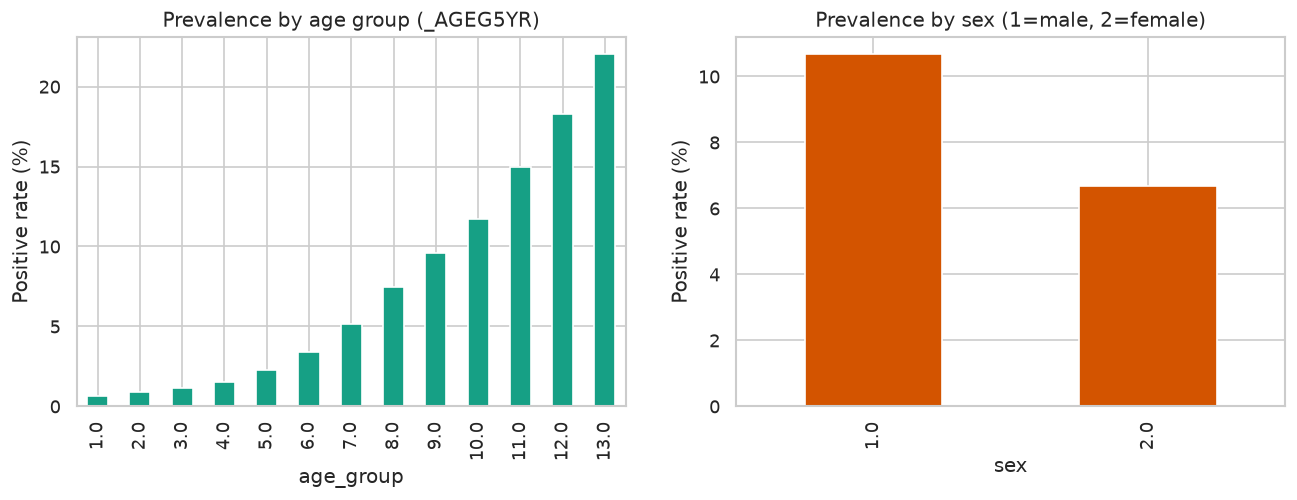

In [10]:
Image(str(C.FIGURES_DIR / "05_prevalence_by_group.png"))

### Interpretation

Prevalence rises sharply with age and is higher for males. These are known
cardiovascular risk patterns and provide face validity for the data, but they
also flag **fairness** considerations that are analysed later.

## 15. Categorical Risk-Factor Association

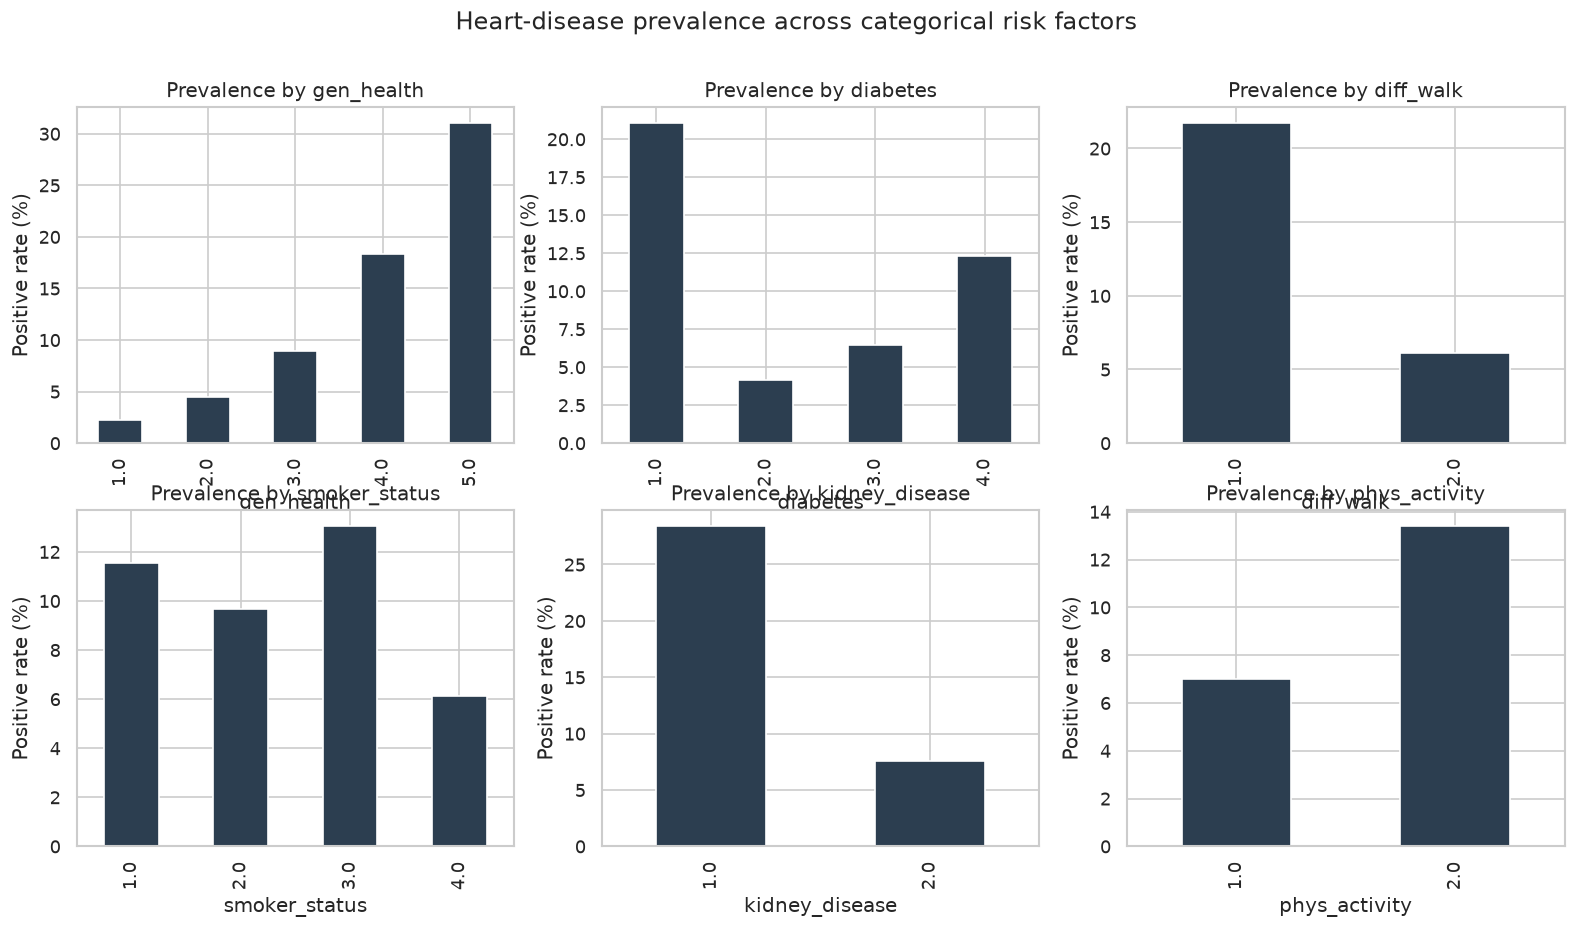

In [11]:
Image(str(C.FIGURES_DIR / "06_categorical_association.png"))

### Interpretation

Poor general health, diabetes, difficulty walking and kidney disease are all
strongly associated with higher heart-disease prevalence, consistent with
clinical expectations and supporting their inclusion as features.

## 16. Feature Correlation

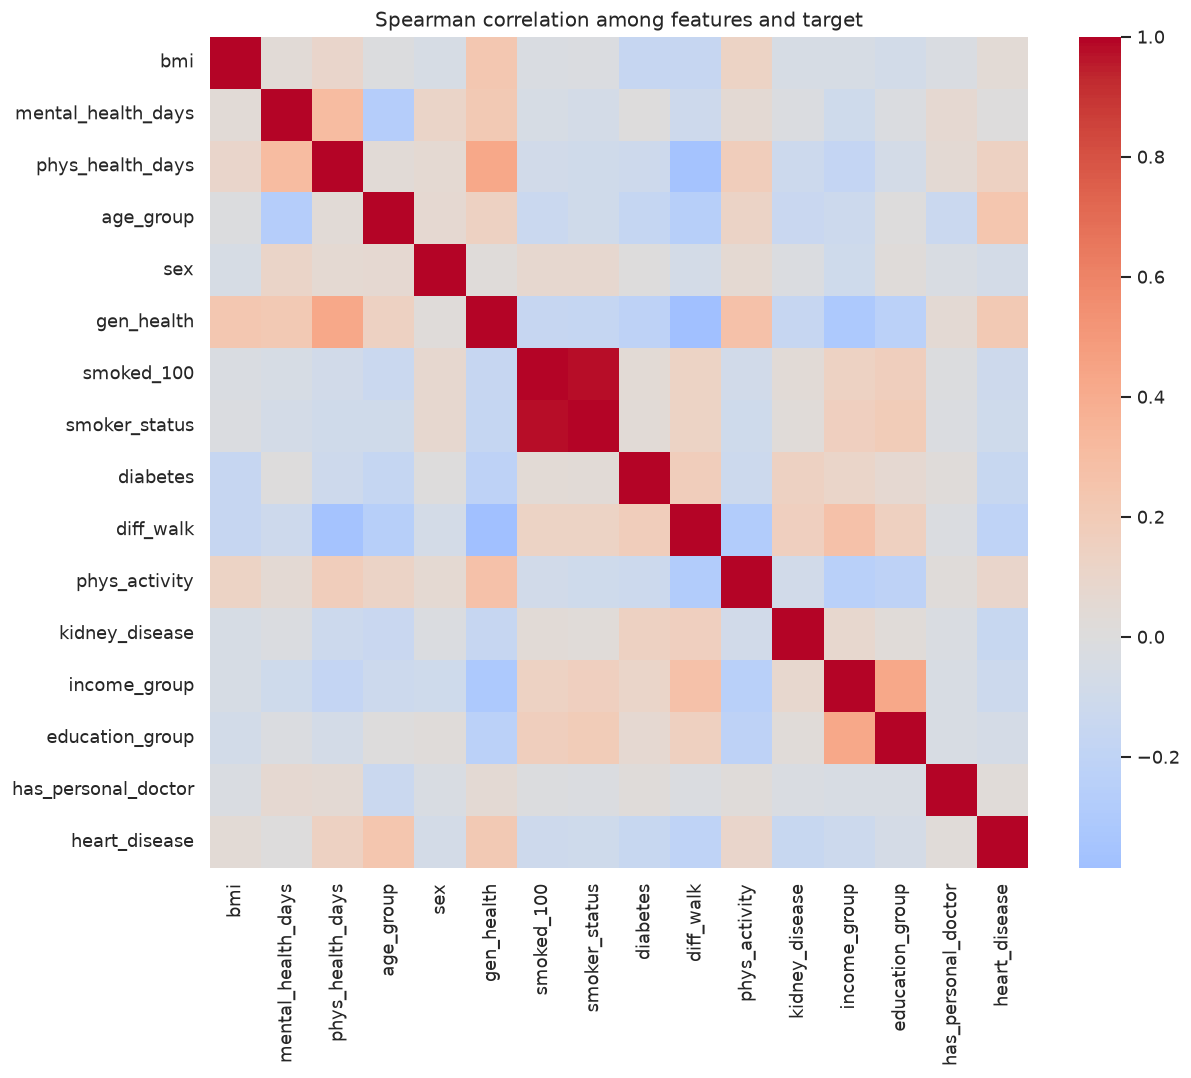

In [12]:
Image(str(C.FIGURES_DIR / "07_correlation_heatmap.png"))

### Interpretation

No pair of features is so highly correlated as to be redundant, so all features
are retained. The strongest single correlations with the target come from
general health, difficulty walking and age.

## 17. Feature Engineering & Temporal Split

The preprocessing pipeline is a scikit-learn `ColumnTransformer`:

- **Continuous** (`bmi`, `mental_health_days`, `phys_health_days`): median
  imputation → standard scaling.
- **Categorical** (survey-coded ordinals/nominals): most-frequent imputation →
  one-hot encoding with `handle_unknown="ignore"`.

The data is split **by survey year** — 2021+2022 for training, 2023 for
testing — so evaluation reflects deployment on a future year.


In [13]:
X_train, X_test, y_train, y_test, train_df, test_df = F.temporal_split(df)
print("Train rows:", f"{len(X_train):,}", "| positive:", f"{y_train.mean():.3%}")
print("Test  rows:", f"{len(X_test):,}", "| positive:", f"{y_test.mean():.3%}")

pre = F.build_preprocessor()
pre.fit(X_train)
n_out = pre.transform(X_train[:5]).shape[1]
print("Transformed feature width:", n_out)

Train rows: 874,169 | positive: 8.588%
Test  rows: 428,738 | positive: 8.469%


Transformed feature width: 53


### Interpretation

Fitting the preprocessor only on the training years guarantees the 2023 test set
is treated as genuinely unseen. One-hot encoding of the survey codes expands the
15 raw features into a wider sparse matrix that the linear and tree models can
consume.

## 18. Data Labeling

In [14]:
print("Labels are taken directly from the CDC-calculated _MICHD variable.")
print("No manual/weak labeling is required.")
print(y_train.value_counts().rename({0:'no CHD/MI',1:'CHD/MI'}))

Labels are taken directly from the CDC-calculated _MICHD variable.
No manual/weak labeling is required.
heart_disease
no CHD/MI    799095
CHD/MI        75074
Name: count, dtype: int64


### Interpretation

Because BRFSS already provides the calculated `_MICHD` indicator, no manual
labeling, crowd-sourcing or weak-supervision step is needed — the labels are
authoritative and consistent across years.

## 19. Model Training & Comparison

Five classifiers are trained, all made imbalance-aware:

- **Logistic Regression** (`class_weight="balanced"`) — interpretable baseline.
- **Decision Tree** (`class_weight="balanced"`).
- **Random Forest** (`class_weight="balanced_subsample"`).
- **Gradient Boosting** (sklearn).
- **XGBoost** (`scale_pos_weight` = neg/pos ratio).

A majority-class dummy is also scored for reference. Training on ~0.87 M rows
takes several minutes.


In [15]:
# Re-uses the exact training routine from src/train.py (single source of truth).
# Training all five models on ~0.87 M rows takes several minutes. If results were
# already produced (reports/model_comparison.csv), reuse them for a fast re-run;
# set FORCE_RETRAIN = True to retrain from scratch.
FORCE_RETRAIN = False
_cmp = C.REPORTS_DIR / "model_comparison.csv"
if _cmp.exists() and not FORCE_RETRAIN:
    results_df = pd.read_csv(_cmp, index_col=0)
    best_name = json.loads((C.MODELS_DIR / "best_model_meta.json").read_text())["best_model"]
    print("Loaded cached results. Best model:", best_name)
else:
    results_df, best_name, best_pipe, _ = T.run(save=True)
results_df[["roc_auc","pr_auc","recall","precision","f1","specificity","brier"]].round(4)

Loaded cached results. Best model: XGBoost


,roc_auc,pr_auc,recall,precision,f1,specificity,brier
model,,,,,,,
MajorityBaseline,0.5000,0.0847,0.0000,0.0000,0.0000,1.0000,0.0847
LogisticRegression,0.8335,0.3152,0.8018,0.2072,0.3294,0.7162,0.1814
DecisionTree,0.7835,0.2637,0.6888,0.2122,0.3245,0.7634,0.1935
RandomForest,0.8282,0.3106,0.7899,0.2076,0.3288,0.7210,0.1799
GradientBoosting,0.8354,0.3193,0.0787,0.5053,0.1361,0.9929,0.0662
XGBoost,0.8364,0.3212,0.8192,0.2032,0.3256,0.7028,0.1817


### Interpretation

The saved results (`reports/model_comparison.csv`) on the 2023 temporal test set:

| Model | ROC-AUC | PR-AUC | Recall | Precision | F1 |
|---|---|---|---|---|---|
| MajorityBaseline | 0.500 | 0.085 | 0.000 | 0.000 | 0.000 |
| LogisticRegression | 0.834 | 0.315 | 0.802 | 0.207 | 0.329 |
| DecisionTree | 0.784 | 0.264 | 0.689 | 0.212 | 0.324 |
| RandomForest | 0.828 | 0.311 | 0.790 | 0.208 | 0.329 |
| GradientBoosting | 0.835 | 0.319 | 0.079 | 0.505 | 0.136 |
| **XGBoost** | **0.836** | **0.321** | **0.819** | 0.203 | 0.326 |

All learners vastly outperform the majority baseline. **XGBoost** achieves the
best PR-AUC and ROC-AUC while maintaining the highest recall (0.82). The
class-weighted logistic-regression baseline is remarkably competitive and far
more interpretable. Gradient Boosting shows high ROC-AUC but very low recall at
the default 0.5 threshold — it ranks well but is poorly calibrated for a fixed
cut-off, which motivates the threshold/calibration discussion below.

## 20. Best Model Selection

In [16]:
meta = json.loads((C.MODELS_DIR / "best_model_meta.json").read_text())
print("Selected model:", meta["best_model"])
print("Selection metric:", meta["selection_metric"], "=", round(meta["pr_auc"],4))

Selected model: XGBoost
Selection metric: pr_auc = 0.3212


### Interpretation

The final model is selected by **PR-AUC**, the most informative single metric for
a rare positive class. XGBoost is chosen; logistic regression is retained as an
interpretable fallback that a clinical reviewer can easily audit.

## 21. ROC and Precision-Recall Curves

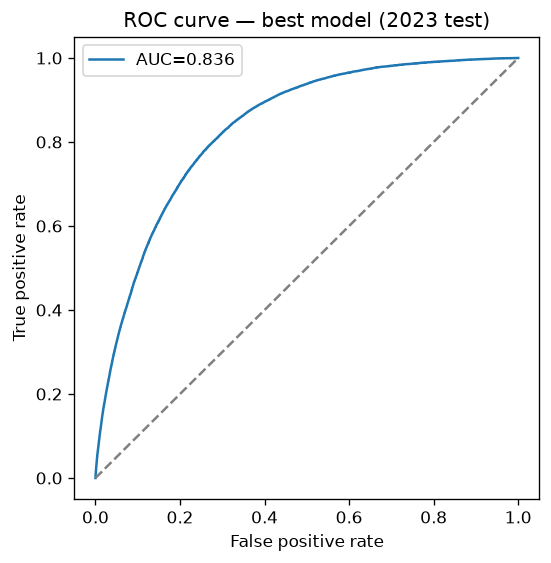

In [17]:
Image(str(C.FIGURES_DIR / "08_roc_curve.png"))

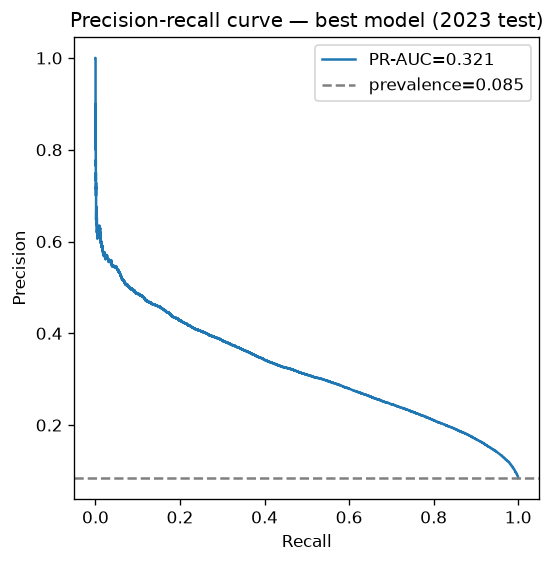

In [18]:
Image(str(C.FIGURES_DIR / "09_pr_curve.png"))

### Interpretation

The ROC-AUC of ~0.84 indicates strong ranking ability. The precision-recall
curve sits well above the ~0.085 prevalence baseline, confirming the model finds
positives far better than chance despite the imbalance.

## 22. Calibration

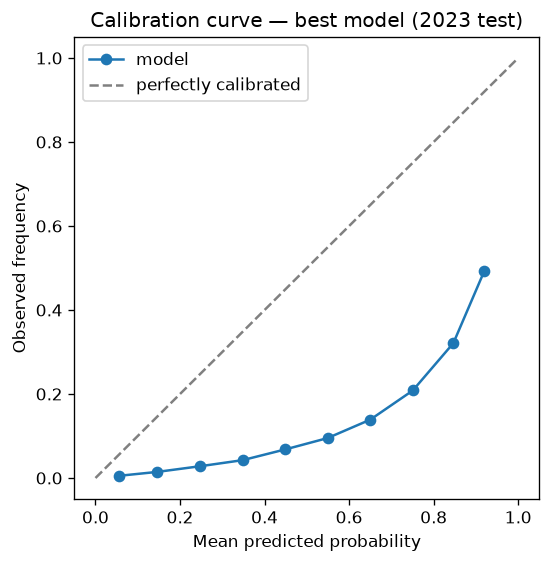

In [19]:
Image(str(C.FIGURES_DIR / "10_calibration.png"))

### Interpretation

Calibration matters because the output is intended as a **risk probability** for
prioritisation. The curve shows reasonable but imperfect calibration; a
production deployment would add probability calibration (e.g. isotonic or
Platt scaling) fitted on a validation split.

## 23. Confusion Matrix

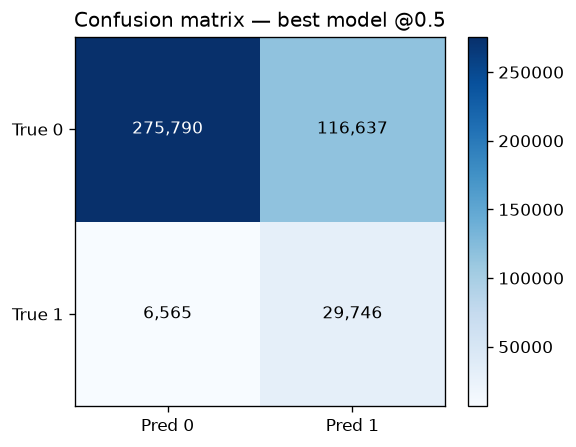

In [20]:
Image(str(C.FIGURES_DIR / "11_confusion_matrix.png"))

### Interpretation

At a 0.5 threshold XGBoost captures ~82% of true heart-disease cases (high
recall) at the cost of many false positives — an acceptable trade-off for a
**screening** tool whose purpose is to avoid missing at-risk individuals. The
operating threshold can be tuned to the screening budget.

## 24. Fairness / Subgroup Analysis

Because age, sex and income are sensitive attributes, model performance is
measured separately across subgroups on the 2023 test set.


,subgroup,n,prevalence,roc_auc,pr_auc,recall,selection_rate
0,sex=male,201395,0.1061,0.8318,0.3562,0.8697,0.4164
1,sex=female,227343,0.0657,0.8307,0.2646,0.7470,0.2750
2,age 18-39,98915,0.0106,0.7696,0.0714,0.1263,0.0088
3,age 40-59,120210,0.0459,0.8168,0.2217,0.5894,0.1626
4,age 60+,202116,0.1448,0.7599,0.3445,0.8892,0.6108


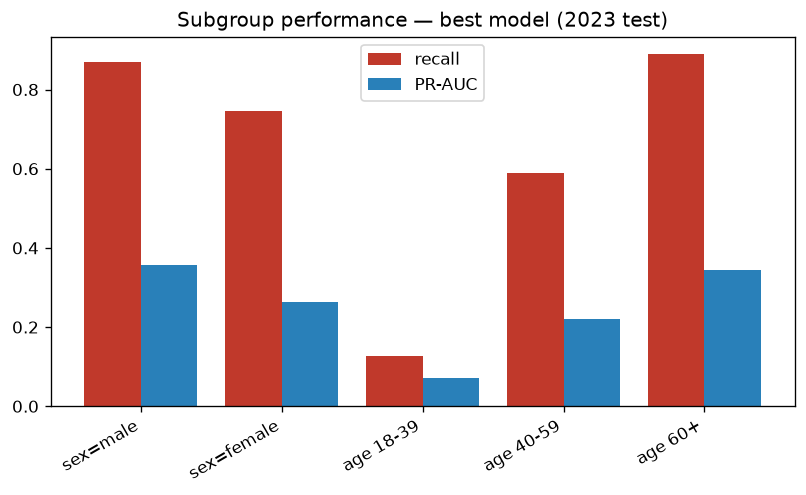

In [21]:
sub = pd.read_csv(C.REPORTS_DIR / "subgroup_metrics.csv")
display(sub.round(4))
Image(str(C.FIGURES_DIR / "12_subgroup_performance.png"))

### Interpretation

Recall is higher for males (0.87) than females (0.75) and much higher for older
adults (age 60+: 0.89) than younger adults (age 18-39: 0.13). The low recall for
young adults is driven by their very low prevalence (~1%) — the model rarely
flags them. This is an important fairness limitation: the tool is most reliable
for older, higher-prevalence groups and should not be used to *rule out* risk in
younger adults. A production system would monitor these subgroup gaps and
consider group-specific thresholds.

## 25. Model Deployment (Design)

- **Serving pattern:** batch scoring. Screening is run periodically over a
  population extract rather than per-request, so a scheduled batch job (e.g.
  SageMaker Batch Transform / a containerised job) is the natural fit.
- **Instance size:** the model is small; a modest CPU instance
  (e.g. `ml.m5.large`, 2 vCPU / 8 GB) comfortably scores hundreds of thousands
  of rows. No GPU is required.
- **Artifact:** the fitted `Pipeline` (preprocessor + classifier) is serialised
  with `joblib` so preprocessing and inference stay in lock-step.


## 26. Model Monitoring (Design)

- **Model quality:** track recall, PR-AUC and calibration on newly labelled data;
  alert if recall drops below an agreed floor.
- **Data drift:** monitor feature distributions (age, BMI, general health) and
  missingness against the training profile using population-stability index.
- **Fairness drift:** re-compute subgroup recall by sex and age each cycle.
- **Infrastructure:** monitor batch-job success, runtime and error rate.


## 27. Model CI/CD (Design)

- **Checkpoints:** data-schema validation → ingestion → training → evaluation
  gate → registration → deployment.
- **Tests:** unit tests for ingestion/harmonisation and leakage exclusion;
  a data-contract test that fails if a required variable is missing for a year;
  an evaluation gate that blocks promotion unless PR-AUC and recall on a fixed
  hold-out exceed the current production model.


## 28. Conclusions and Key Findings

- A leakage-controlled pipeline on harmonised BRFSS 2021-2023 data predicts
  reported heart disease with **ROC-AUC ≈ 0.84** and **PR-AUC ≈ 0.32** on a
  genuinely unseen **future year (2023)**.
- **XGBoost** is the best overall model; a class-weighted **logistic regression**
  is a close, interpretable second and makes a strong deployable baseline.
- All models dramatically beat the majority-class baseline (PR-AUC 0.085),
  satisfying the project's minority-class-detection goal.
- Performance is **stable across survey years**, evidence of temporal
  generalisation.
- **Fairness analysis** reveals meaningful recall gaps across sex and age that
  must be disclosed and monitored.


## 29. Limitations and Future Improvements

**Limitations**
- Self-reported, cross-sectional survey data; the target reflects *diagnosed and
  reported* disease, so undiagnosed cases pollute the negative class.
- Hypertension and cholesterol — strong clinical predictors — were dropped for
  cross-year consistency because BRFSS omits them in 2022.
- Results are US-specific and not clinically validated.

**Future improvements**
1. Add probability **calibration** and threshold optimisation tied to a defined
   screening budget.
2. Train **odd-year-only** models that include blood pressure and cholesterol,
   and compare against the harmonised model.
3. Incorporate **survey weights** and evaluate with complex-survey methods.
4. Add SHAP-based explanations and automated **fairness-gate** checks to CI/CD.


## 30. Executive Summary

This project delivers a reproducible, leakage-controlled MLOps pipeline that
screens adults for likely coronary heart disease / myocardial infarction from
routine BRFSS survey features. Trained on 2021-2022 and validated on a held-out
2023 temporal test set, the chosen XGBoost model reaches ROC-AUC ≈ 0.84 /
PR-AUC ≈ 0.32 with ~82% recall, decisively beating the majority baseline while
remaining stable across years. Subgroup analysis transparently documents
performance gaps by sex and age. The accompanying design document specifies the
data engineering, deployment, monitoring, CI/CD and security posture required to
operate the model responsibly as an **academic screening exercise** — explicitly
not a clinical device.
